# Multi-Robot Pick-and-Deliver with Obstacle and Collision Avoidance in Shared Aisles


### Group members:  Ardra Suresh, Jinsy Panamkattu, Neethu Joseph Chully, Reshma Mani ###


## 1. Setup and configuration

Install the libraries 

```
pip install torch gymnasium numpy matplotlib pandas pillow
```



In [1]:
import copy, time, random, os
from collections import deque

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib import animation
from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg
from matplotlib.patches import Circle, Rectangle
from PIL import Image
from IPython.display import HTML, display

import gymnasium as gym
from gymnasium import spaces

QUICK = False         
SEED = 0
os.makedirs("results", exist_ok=True)

if QUICK:
    STEPS_2, STEPS_4, STEPS_ABL, EVAL_EVERY, EVAL_EPISODES = 4000, 4000, 3000, 2000, 10
else:
    STEPS_2   = 150_000   
    STEPS_4   = 150_000  
    STEPS_ABL = 60_000   
    EVAL_EVERY, EVAL_EPISODES = 10_000, 100


ENV_KW = dict(n_packages=2,     
              n_obstacles=3,    
              max_steps=150)    

RUN_MULTISEED = True    

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)

set_seed(SEED)
torch.set_num_threads(1)
print("torch", torch.__version__, "| gymnasium", gym.__version__, "| QUICK =", QUICK)

torch 2.14.1 | gymnasium 1.3.0 | QUICK = False


## 2. Warehouse layouts

A layout is a small text map: `#` is a wall or shelf, `.` is a free cell. 


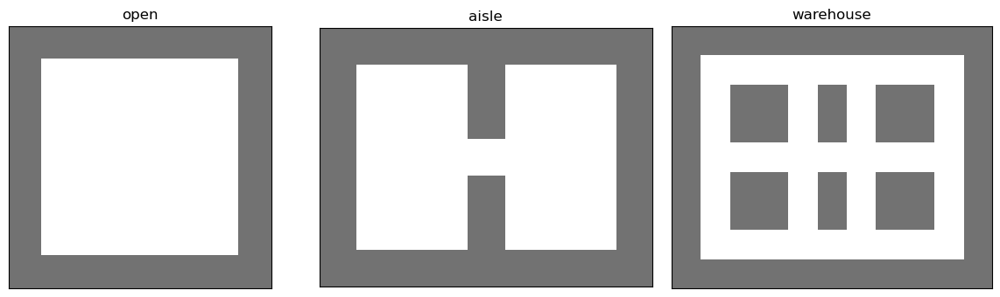

In [2]:
LAYOUTS = {
    "open": [
        "########",
        "#......#",
        "#......#",
        "#......#",
        "#......#",
        "#......#",
        "#......#",
        "########",
    ],
    "aisle": [
        "#########",
        "#...#...#",
        "#...#...#",
        "#.......#",     # <- the single door in the middle wall = shared aisle
        "#...#...#",
        "#...#...#",
        "#########",
    ],
    "warehouse": [
        "###########",
        "#.........#",
        "#.##.#.##.#",
        "#.##.#.##.#",
        "#.........#",
        "#.##.#.##.#",
        "#.##.#.##.#",
        "#.........#",
        "###########",
    ],
}

def layout_array(name):
    return np.array([[1 if ch == "#" else 0 for ch in row] for row in LAYOUTS[name]], dtype=np.int8)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, name in zip(axes, LAYOUTS):
    ax.imshow(layout_array(name), cmap="Greys", vmin=0, vmax=1.6)
    ax.set_title(name); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

## 3. The environment

In [3]:
MOVES = np.array([[-1, 0], [1, 0], [0, -1], [0, 1], [0, 0]])   
N_ACTIONS, MAX_ROBOTS, PATCH = 5, 6, 5
HALF = PATCH // 2
CH = 4                                        
EXTRA_DIM = 2 + 2 + 1 + MAX_ROBOTS + N_ACTIONS   
COLORS = ["#e63946", "#1d78dc", "#2a9d50", "#f0a014", "#9650c8", "#14b4be"]

# reward constants 
R_GOAL, R_STEP, R_COLLISION, R_WALL, R_PROGRESS, R_TEAM = 10.0, -0.05, -2.0, -0.5, 0.1, 2.0
R_PICKUP = 5.0                                

def bfs_dist(grid, goal):
    """Shortest-path distance from every cell to `goal`."""
    dist = np.full(grid.shape, 10 ** 6, dtype=np.int32)
    dist[goal[0], goal[1]] = 0
    q = deque([tuple(goal)])
    while q:
        r, c = q.popleft()
        for dr, dc in MOVES[:4]:
            nr, nc = r + dr, c + dc
            if grid[nr, nc] == 0 and dist[nr, nc] > dist[r, c] + 1:
                dist[nr, nc] = dist[r, c] + 1
                q.append((nr, nc))
    return dist


def is_connected(grid):
    
    free = [(r, c) for r in range(grid.shape[0]) for c in range(grid.shape[1]) if grid[r, c] == 0]
    d = bfs_dist(grid, free[0])
    return all(d[r, c] < 10 ** 6 for r, c in free)


class WarehouseEnv(gym.Env):
   
    metadata = {"render_modes": ["rgb_array", "ansi"], "render_fps": 4}

    def __init__(self, layout="aisle", n_robots=2, max_steps=150, cross=True,
                 use_shaping=True, collision_penalty=R_COLLISION, n_packages=2, n_obstacles=3,
                 pickup_reward=R_PICKUP, render_mode=None, seed=0):
        super().__init__()
        assert n_robots <= MAX_ROBOTS
        assert render_mode is None or render_mode in self.metadata["render_modes"]
        self.layout_name, self.base_grid = layout, layout_array(layout)
        self.grid = self.base_grid.copy()                   
        self.H, self.W = self.base_grid.shape
        self.n, self.max_steps, self.cross = n_robots, max_steps, cross
        self.K, self.n_obstacles = n_packages, n_obstacles   
        self.use_shaping, self.collision_penalty, self.pickup_reward = use_shaping, collision_penalty, pickup_reward
        self.render_mode = render_mode
        self.obstacles = []

        self.action_space = spaces.MultiDiscrete([N_ACTIONS] * n_robots)
        self.observation_space = spaces.Dict({
            "patch": spaces.Box(0.0, 1.0, shape=(n_robots, CH, PATCH, PATCH), dtype=np.float32),
            "extra": spaces.Box(-1.0, 1.0, shape=(n_robots, EXTRA_DIM), dtype=np.float32),
            "mask":  spaces.MultiBinary((n_robots, N_ACTIONS)),
        })
        super().reset(seed=seed)         
        self.trail, self._collided = [], np.zeros(n_robots, bool)

    
    def reset(self, *, seed=None, options=None):
        """New episode: random starts, goals, packages and obstacles.
        Returns (obs, info) as required by Gymnasium."""
        super().reset(seed=seed)        
        self.set_scene(*self._sample_scene())
        return self._obs(), {"t": 0, "collisions": 0}

    def _draw(self, pool, used, avoid=None):
        options = [p for p in pool if p not in used and p != avoid]
        return options[int(self.np_random.integers(len(options)))]

    def _sample_scene(self):
        free = [(r, c) for r in range(self.H) for c in range(self.W) if self.base_grid[r, c] == 0]
        need = self.n * (2 + self.K) + self.n_obstacles
        assert need <= len(free), f"'{self.layout_name}' has {len(free)} free cells but this setup needs {need}"
        # starts and goals: with cross=True every robot starts on one side and its goal is on the OTHER side
        mid = self.W // 2
        pools = [[p for p in free if p[1] < mid], [p for p in free if p[1] > mid]]
        used_s, used_g, starts, goals = set(), set(), [], []
        for _ in range(self.n):
            if self.cross:
                side = int(self.np_random.integers(2)); sp, gp = pools[side], pools[1 - side]
            else:
                sp = gp = free
            s = self._draw(sp, used_s); used_s.add(s)
            g = self._draw(gp, used_g, avoid=s); used_g.add(g)
            starts.append(s); goals.append(g)
        # packages: K per robot, anywhere on the map (so robots must cross the aisle to collect them)
        used = used_s | used_g
        packages = []
        for _ in range(self.n):
            row = []
            for _ in range(self.K):
                p = self._draw(free, used); used.add(p); row.append(p)
            packages.append(row)
        return starts, goals, packages, self._draw_obstacles(free, used)

    def _draw_obstacles(self, free, used):
        """Random obstacle cells, re-drawn until the free space is still one connected region."""
        if self.n_obstacles == 0:
            return []
        cand = [p for p in free if p not in used]
        for _ in range(300):
            pick = self.np_random.choice(len(cand), size=self.n_obstacles, replace=False)
            obst = [cand[k] for k in pick]
            g = self.base_grid.copy()
            for r, c in obst:
                g[r, c] = 1
            if is_connected(g):
                return obst
        raise RuntimeError("could not place the obstacles without cutting the map in two")

    def set_scene(self, pos, goals, packages=None, obstacles=None):
        """Place everything by hand (used by reset() and by the unit tests)."""
        self.pos, self.goals = np.array(pos, dtype=int), np.array(goals, dtype=int)
        self.obstacles = [tuple(o) for o in (obstacles or [])]
        self.grid = self.base_grid.copy()
        for r, c in self.obstacles:
            self.grid[r, c] = 1
        self.padded_walls = np.pad(self.grid, HALF, constant_values=1).astype(np.float32)
        self.pkg_pos = np.array(packages if packages is not None else [], dtype=int).reshape(self.n, self.K, 2)
        self.pkg_left = np.ones((self.n, self.K), bool)           
        self.dist = [bfs_dist(self.grid, g) for g in self.goals]  
        self.pkg_dist = [[bfs_dist(self.grid, p) for p in self.pkg_pos[i]] for i in range(self.n)]
        self.active = np.ones(self.n, bool)
        self.last_action = np.full(self.n, 4)
        self.picked = np.zeros(self.n, int)
        self.t, self.collisions = 0, 0
        self.trail = [[tuple(p)] for p in self.pos]              
        self._collided = np.zeros(self.n, bool)

    def target_of(self, i):
        """What robot i is heading for right now: its NEAREST remaining package (by walking
        distance), or its goal once every package is collected. Returns (position, distance map)."""
        r, c = self.pos[i]
        best = None
        for j in range(self.K):
            if self.pkg_left[i, j]:
                d = self.pkg_dist[i][j][r, c]
                if best is None or d < best[0]:
                    best = (d, j)
        if best is not None:
            return self.pkg_pos[i, best[1]], self.pkg_dist[i][best[1]]
        return self.goals[i], self.dist[i]

   
    def step(self, actions):
        """Returns obs, rewards (N,), terminated, truncated, info."""
        N = self.n
        rewards = np.zeros(N, np.float32)
        active_before = self.active.copy()
        old_pos, target = self.pos.copy(), self.pos.copy()
        dist_old = [self.target_of(i)[1] if self.active[i] else None for i in range(N)]   

        # 1) intended moves; walls and obstacles cancel the move
        for i in range(N):
            if not self.active[i]:
                continue
            a = int(actions[i]); self.last_action[i] = a
            nxt = self.pos[i] + MOVES[a]
            if self.grid[nxt[0], nxt[1]] == 1:
                rewards[i] += R_WALL; nxt = self.pos[i]
            target[i] = nxt

        # 2) robot-robot conflicts: all involved MOVERS stay. Repeat until stable.
        collided = np.zeros(N, bool)
        changed = True
        while changed:
            changed, bad = False, set()
            for i in range(N):
                if not self.active[i]: continue
                for j in range(i + 1, N):
                    if not self.active[j]: continue
                    same = (target[i] == target[j]).all()                                   
                    swap = (target[i] == self.pos[j]).all() and (target[j] == self.pos[i]).all()  
                    if same or swap:
                        for k in (i, j):
                            if not (target[k] == self.pos[k]).all():   
                                bad.add(k)
            for k in bad:
                target[k] = self.pos[k]; collided[k] = True; changed = True
        rewards[collided] += self.collision_penalty
        self.collisions += int(collided.sum())
        self._collided = collided

        # 3) apply moves; step cost; progress shaping; pick up packages
        self.pos = target
        picked_now = np.zeros(N, int)
        for i in range(N):
            if not active_before[i]: continue
            rewards[i] += R_STEP
            if self.use_shaping:                      
                d_old = dist_old[i][old_pos[i][0], old_pos[i][1]]
                d_new = dist_old[i][self.pos[i][0], self.pos[i][1]]
                rewards[i] += R_PROGRESS * (d_old - d_new)
            for j in range(self.K):                   
                if self.pkg_left[i, j] and (self.pkg_pos[i, j] == self.pos[i]).all():
                    self.pkg_left[i, j] = False; picked_now[i] += 1
                    rewards[i] += self.pickup_reward
            self.trail[i].append(tuple(self.pos[i]))
        self.picked += picked_now

        # 4) delivery: the goal only counts once ALL of the robot's packages are collected
        all_collected = ~self.pkg_left.any(axis=1)
        reached = active_before & all_collected & (self.pos == self.goals).all(axis=1)
        rewards[reached] += R_GOAL
        self.active = active_before & ~reached

        self.t += 1
        success = not self.active.any()
        if success:
            rewards[active_before] += R_TEAM
        terminated = bool(success)                          
        truncated = bool((not success) and self.t >= self.max_steps)   
        info = {"active_before": active_before, "reached": reached, "picked": picked_now,
                "packages_picked": int(self.picked.sum()), "packages_total": self.n * self.K,
                "collisions": self.collisions, "success": success, "t": self.t,
                "team_reward": float(rewards.sum())}
        return self._obs(), rewards, terminated, truncated, info

    
    def action_mask(self, i):
        m = np.ones(N_ACTIONS, bool)
        for a in range(4):
            nxt = self.pos[i] + MOVES[a]
            if self.grid[nxt[0], nxt[1]] == 1:
                m[a] = False
        return m

    def _obs(self):
        N = self.n
        robots = np.zeros((self.H, self.W), np.float32)
        for i in range(N):
            if self.active[i]:
                robots[self.pos[i][0], self.pos[i][1]] = 1.0
        pr = np.pad(robots, HALF)
        patches = np.zeros((N, CH, PATCH, PATCH), np.float32)
        extras = np.zeros((N, EXTRA_DIM), np.float32)
        masks = np.ones((N, N_ACTIONS), bool)
        for i in range(N):
            if not self.active[i]:
                continue
            masks[i] = self.action_mask(i)
            r, c = self.pos[i] + HALF
            win = (slice(r - HALF, r + HALF + 1), slice(c - HALF, c + HALF + 1))
            patches[i, 0] = self.padded_walls[win]                
            patches[i, 1] = pr[win]                               
            patches[i, 1, HALF, HALF] = 0.0                       
            pk = np.zeros((self.H, self.W), np.float32)           
            for j in range(self.K):
                if self.pkg_left[i, j]:
                    pk[self.pkg_pos[i, j][0], self.pkg_pos[i, j][1]] = 1.0
            patches[i, 2] = np.pad(pk, HALF)[win]
            rel_g = self.goals[i] - self.pos[i]                  
            if abs(rel_g[0]) <= HALF and abs(rel_g[1]) <= HALF:
                patches[i, 3, rel_g[0] + HALF, rel_g[1] + HALF] = 1.0
            rel_t = self.target_of(i)[0] - self.pos[i]           
            extras[i, 0], extras[i, 1] = rel_t[0] / self.H, rel_t[1] / self.W
            extras[i, 2], extras[i, 3] = rel_g[0] / self.H, rel_g[1] / self.W
            extras[i, 4] = (self.K - self.pkg_left[i].sum()) / self.K if self.K else 1.0   
            extras[i, 5 + i] = 1.0                                
            extras[i, 5 + MAX_ROBOTS + self.last_action[i]] = 1.0 
        return {"patch": patches, "extra": extras, "mask": masks}

    
    def render(self):
        """render_mode='rgb_array'."""
        if self.render_mode == "rgb_array":
            return self._render_rgb()
        if self.render_mode == "ansi":
            return self._render_ansi()
        return None

    def _render_ansi(self):
        rows = [["#" if v else "." for v in row] for row in self.base_grid]
        for r, c in self.obstacles:
            rows[r][c] = "X"                                        
        for i in range(self.n):
            gr, gc = self.goals[i]; rows[gr][gc] = "abcdef"[i]      
            for j in range(self.K):
                if self.pkg_left[i, j]:
                    pr_, pc_ = self.pkg_pos[i, j]; rows[pr_][pc_] = "p"  
        for i in range(self.n):
            if self.active[i]:
                r, c = self.pos[i]; rows[r][c] = str(i)            
        return "\n".join("".join(r) for r in rows)

    def _render_rgb(self):
        fig = Figure(figsize=(self.W * 0.7, self.H * 0.7 + 0.5), dpi=100)
        FigureCanvasAgg(fig)
        ax = fig.add_axes([0.01, 0.01, 0.98, 0.87])
        ax.imshow(self.base_grid, cmap="Greys", vmin=0, vmax=1.6)
        for r, c in self.obstacles:                               
            ax.add_patch(Rectangle((c - .42, r - .42), .84, .84, fc="#a0693a", ec="#5c3a1e", lw=1.5, zorder=2))
            ax.plot([c - .3, c + .3], [r - .3, r + .3], color="#5c3a1e", lw=1, zorder=2)
            ax.plot([c - .3, c + .3], [r + .3, r - .3], color="#5c3a1e", lw=1, zorder=2)
        for i in range(self.n):
            col, (gr, gc) = COLORS[i], self.goals[i]
            arrived = not self.active[i]
            ax.add_patch(Rectangle((gc - .38, gr - .38), .76, .76, ec=col, lw=2.5,
                                   fc=col if arrived else "none", alpha=0.45 if arrived else 1.0))
            for j in range(self.K):                                 
                if self.pkg_left[i, j]:
                    pr_, pc_ = self.pkg_pos[i, j]
                    ax.add_patch(Rectangle((pc_ - .2, pr_ - .2), .4, .4, fc=col, ec="black", lw=1.2, zorder=3))
            tr = np.array(self.trail[i]) if len(self.trail) > i else np.zeros((0, 2))
            if len(tr) > 1:
                ax.plot(tr[:, 1], tr[:, 0], color=col, lw=2, alpha=0.35, zorder=2)
            if arrived:
                ax.text(gc, gr, "\u2713", color="white", ha="center", va="center", fontsize=12, weight="bold")
            else:
                r, c = self.pos[i]
                ax.add_patch(Circle((c, r), .33, color=col, zorder=4))
                ax.text(c, r, str(i), color="white", ha="center", va="center", fontsize=10, weight="bold", zorder=5)
                if self.K:
                    ax.text(c + .36, r + .4, f"{self.picked[i]}/{self.K}", color="black", ha="center",
                            va="center", fontsize=7, weight="bold", zorder=6,
                            bbox=dict(boxstyle="round,pad=0.1", fc="white", ec=col, lw=1))
                if self._collided[i]:                                
                    ax.add_patch(Circle((c, r), .47, fill=False, ec="red", lw=3, zorder=6))
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"t = {self.t}   packages {int(self.picked.sum())}/{self.n * self.K}   "
                     f"delivered {int((~self.active).sum())}/{self.n}   collisions {self.collisions}", fontsize=9)
        fig.canvas.draw()
        return np.asarray(fig.canvas.buffer_rgba())[..., :3].copy()


gym.registry.pop("MultiRobotWarehouse-v0", None)            
gym.register(id="MultiRobotWarehouse-v0", entry_point=WarehouseEnv)

### Running environment 

action space     : MultiDiscrete([5 5])
observation space: {'extra': (2, 16), 'mask': (2, 5), 'patch': (2, 4, 5, 5)}
start positions  : [[3, 2], [1, 5]]
goal positions   : [[4, 7], [1, 3]]
packages robot 0 : [[5, 2], [5, 6]] | packages robot 1: [[2, 3], [2, 6]]
obstacles        : [(4, 1), (3, 6), (3, 1)]
current target of each robot: [[5, 2], [2, 6]]
positions after one step: [[3, 3], [1, 6]]
rewards: [-0.15  0.05] | terminated: False | truncated: False | collisions so far: 0 | packages picked: 0


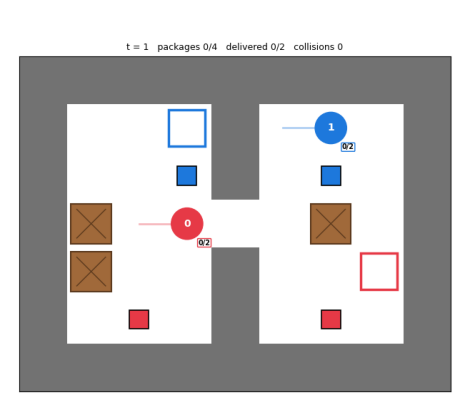

#########
#..b#.1.#
#..p#.p.#
#X.0..X.#
#X..#..a#
#.p.#.p.#
#########


In [4]:
env = gym.make("MultiRobotWarehouse-v0", layout="aisle", n_robots=2, render_mode="rgb_array",
               disable_env_checker=True, **ENV_KW)   
obs, info = env.reset(seed=1)
raw = env.unwrapped                                   
print("action space     :", env.action_space)
print("observation space:", {k: v.shape for k, v in env.observation_space.spaces.items()})
print("start positions  :", raw.pos.tolist())
print("goal positions   :", raw.goals.tolist())
print("packages robot 0 :", raw.pkg_pos[0].tolist(), "| packages robot 1:", raw.pkg_pos[1].tolist())
print("obstacles        :", raw.obstacles)
print("current target of each robot:", [raw.target_of(i)[0].tolist() for i in range(raw.n)])
obs, rew, terminated, truncated, info = env.step([3, 3])     
print("positions after one step:", raw.pos.tolist())
print("rewards:", rew, "| terminated:", terminated, "| truncated:", truncated,
      "| collisions so far:", info["collisions"], "| packages picked:", info["packages_picked"])
plt.figure(figsize=(6, 5)); plt.imshow(env.render()); plt.axis("off"); plt.show()
print(raw._render_ansi())     

## 4. Unit tests for the rules


In [5]:
def make_test_env(layout, pos, goals, packages=None, obstacles=None):
    """Build a hand-made situation: positions, goals, (optional) packages and obstacles."""
    K = 0 if packages is None else len(packages[0])
    e = WarehouseEnv(layout, len(pos), n_packages=K, n_obstacles=0); e.reset(seed=0)
    e.set_scene(pos, goals, packages, obstacles)
    return e

def test_vertex_conflict():
    e = make_test_env("open", [(3, 1), (3, 3)], [(3, 5), (3, 6)])
    e.step([3, 2])                                  
    assert (e.pos == [[3, 1], [3, 3]]).all() and e.collisions == 2

def test_swap_conflict():
    e = make_test_env("open", [(3, 1), (3, 2)], [(3, 5), (3, 6)])
    e.step([3, 2])                                  
    assert (e.pos == [[3, 1], [3, 2]]).all() and e.collisions == 2

def test_wall_blocks():
    e = make_test_env("open", [(1, 1), (5, 5)], [(3, 5), (3, 6)])
    e.step([0, 4])                                  
    assert (e.pos[0] == [1, 1]).all()

def test_goal_and_success():
    e = make_test_env("open", [(3, 1), (5, 5)], [(3, 2), (5, 6)])
    _, r, terminated, truncated, info = e.step([3, 3])
    assert info["reached"].all() and terminated and not truncated and info["success"] and r[0] > 9

def test_wait_yield():
    e = make_test_env("open", [(3, 1), (3, 3)], [(3, 5), (3, 6)])
    e.step([3, 4])                                  
    assert e.collisions == 0 and (e.pos[0] == [3, 2]).all()

def test_pickup_then_deliver():
    e = make_test_env("open", [(3, 1), (5, 5)], [(3, 3), (5, 3)], packages=[[(3, 2)], [(5, 6)]])
    assert (e.target_of(0)[0] == [3, 2]).all()                      
    _, r, _, _, info = e.step([3, 3])                                
    assert info["picked"].tolist() == [1, 1] and abs(r[0] - 5.05) < 1e-4   
    assert not info["reached"].any() and (e.target_of(0)[0] == [3, 3]).all()   
    _, r, _, _, info = e.step([3, 2])
    assert info["reached"][0] and abs(r[0] - 10.05) < 1e-4          

def test_goal_needs_all_packages():
    e = make_test_env("open", [(3, 1), (5, 5)], [(3, 2), (5, 3)], packages=[[(3, 5)], [(5, 6)]])
    _, _, _, _, info = e.step([3, 4])                                
    assert not info["reached"][0] and e.active[0]

def test_obstacle_blocks():
    e = make_test_env("open", [(3, 1), (5, 5)], [(3, 5), (5, 3)], obstacles=[(3, 2)])
    assert not e.action_mask(0)[3]                                  
    e.step([3, 4]); assert (e.pos[0] == [3, 1]).all()               

def test_obstacles_keep_map_connected():
    for layout in ("open", "aisle", "warehouse"):
        env = WarehouseEnv(layout, 4, n_packages=2, n_obstacles=4)
        for s in range(50):
            env.reset(seed=s)
            assert is_connected(env.grid)
            for i in range(4):
                assert env.dist[i][tuple(env.pos[i])] < 10 ** 6      
                assert all(env.pkg_dist[i][j][tuple(env.pos[i])] < 10 ** 6 for j in range(2))   

def test_gymnasium_api():
    e = WarehouseEnv("aisle", 2, **ENV_KW)
    out = e.reset(seed=0)
    assert isinstance(e, gym.Env) and len(out) == 2                  
    assert e.observation_space.contains(out[0])
    o, r, terminated, truncated, info = e.step(e.action_space.sample())
    assert e.observation_space.contains(o) and r.shape == (2,)
    assert isinstance(terminated, bool) and isinstance(truncated, bool)

def test_truncation():
    e = WarehouseEnv("open", 1, max_steps=3); e.reset(seed=0)
    for _ in range(3):
        _, _, terminated, truncated, _ = e.step([4])                  
    assert truncated and not terminated

def test_reset_seed_reproducible():
    e = WarehouseEnv("aisle", 3, **ENV_KW); e.reset(seed=7)
    a = (e.pos.copy(), e.goals.copy(), e.pkg_pos.copy(), list(e.obstacles))
    e.reset(seed=7)
    assert (a[0] == e.pos).all() and (a[1] == e.goals).all() and (a[2] == e.pkg_pos).all() and a[3] == e.obstacles

for f in [test_vertex_conflict, test_swap_conflict, test_wall_blocks, test_goal_and_success, test_wait_yield,
          test_pickup_then_deliver, test_goal_needs_all_packages, test_obstacle_blocks,
          test_obstacles_keep_map_connected, test_gymnasium_api, test_truncation, test_reset_seed_reproducible]:
    f(); print("PASS", f.__name__)

PASS test_vertex_conflict
PASS test_swap_conflict
PASS test_wall_blocks
PASS test_goal_and_success
PASS test_wait_yield
PASS test_pickup_then_deliver
PASS test_goal_needs_all_packages
PASS test_obstacle_blocks
PASS test_obstacles_keep_map_connected
PASS test_gymnasium_api
PASS test_truncation
PASS test_reset_seed_reproducible


### Rendering the world

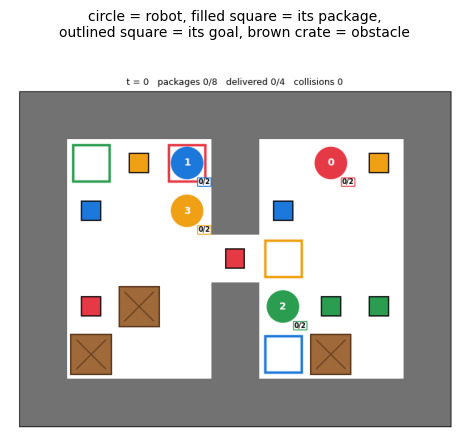

In [6]:
env = WarehouseEnv("aisle", n_robots=4, render_mode="rgb_array", **ENV_KW); env.reset(seed=3)
plt.figure(figsize=(6, 5)); plt.imshow(env.render()); plt.axis("off")
plt.title("circle = robot, filled square = its package,\noutlined square = its goal, brown crate = obstacle", fontsize=10)
plt.show()

## 5. Baselines and the evaluation function


In [7]:
_rng = np.random.default_rng(123)

def random_policy(env, obs):
    return [int(_rng.choice(np.flatnonzero(obs["mask"][i]))) for i in range(env.n)]

def greedy_policy(env, obs):
    acts = []
    for i in range(env.n):
        if not env.active[i]:
            acts.append(4); continue
        _, dm = env.target_of(i)                      
        r, c = env.pos[i]
        best, best_d = 4, dm[r, c]
        for a in range(4):
            nr, nc = r + MOVES[a][0], c + MOVES[a][1]
            if dm[nr, nc] < best_d:
                best, best_d = a, dm[nr, nc]
        acts.append(best)
    return acts


def evaluate(policy, layout, n_robots, episodes=100, seed0=10_000, cross=True, **env_kw):
    env = WarehouseEnv(layout, n_robots, cross=cross, **{**ENV_KW, **env_kw})
    succ, coll, length, cost, picked, delivered = [], [], [], [], [], []
    for ep in range(episodes):
        obs, info = env.reset(seed=seed0 + ep)
        done, robot_steps = False, 0
        while not done:
            robot_steps += int(env.active.sum())
            obs, _, terminated, truncated, info = env.step(policy(env, obs))
            done = terminated or truncated
        succ.append(info["success"]); coll.append(info["collisions"])
        length.append(info["t"]); cost.append(robot_steps)
        picked.append(info["packages_picked"] / max(1, info["packages_total"]))
        delivered.append(env.K * int((~env.active).sum()))      
    succ = np.array(succ)
    return {"success_rate": float(succ.mean()),
            "deadlock_or_timeout_rate": float(1 - succ.mean()),
            "packages_picked_frac": float(np.mean(picked)),
            "collisions_per_episode": float(np.mean(coll)),
            "avg_makespan": float(np.mean(length)),
            "sum_of_costs": float(np.mean(cost)),
            "throughput_per_100_steps": float(100 * np.sum(delivered) / max(1, np.sum(length)))}

rows = []
for n in (2, 4):
    for name, pol in [("random", random_policy), ("shortest_path", greedy_policy)]:
        rows.append({"policy": name, "n_robots": n, **evaluate(pol, "aisle", n, EVAL_EPISODES)})
baseline_df = pd.DataFrame(rows).round(2)
baseline_df

,policy,n_robots,success_rate,deadlock_or_timeout_rate,packages_picked_frac,collisions_per_episode,avg_makespan,sum_of_costs,throughput_per_100_steps
0,random,2,0.10,0.90,0.73,8.24,147.00,278.10,0.68
1,shortest_path,2,0.49,0.51,0.74,148.16,82.86,163.91,2.37
2,random,4,0.00,1.00,0.60,45.77,150.00,573.47,0.73
3,shortest_path,4,0.01,0.99,0.40,533.81,148.66,549.86,0.48


## 6. The DQN algorithm


In [8]:
class DuelingQNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(CH, 16, 3, padding=1), nn.ReLU(),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.Flatten())
        self.fc = nn.Sequential(nn.Linear(32 * PATCH * PATCH + EXTRA_DIM, 128), nn.ReLU())
        self.V = nn.Linear(128, 1)            
        self.A = nn.Linear(128, N_ACTIONS)    

    def forward(self, patch, extra):
        h = self.fc(torch.cat([self.conv(patch), extra], dim=-1))
        a = self.A(h)
        return self.V(h) + a - a.mean(dim=-1, keepdim=True)


class Replay:
    
    def __init__(self, cap):
        self.cap, self.n, self.i = cap, 0, 0
        self.p  = np.zeros((cap, CH, PATCH, PATCH), np.float32); self.p2 = np.zeros_like(self.p)
        self.e  = np.zeros((cap, EXTRA_DIM), np.float32);       self.e2 = np.zeros_like(self.e)
        self.a  = np.zeros(cap, np.int64);  self.r = np.zeros(cap, np.float32)
        self.d  = np.zeros(cap, np.float32); self.m2 = np.zeros((cap, N_ACTIONS), bool)

    def add(self, p, e, a, r, p2, e2, d, m2):
        k = self.i
        self.p[k], self.e[k], self.a[k], self.r[k] = p, e, a, r
        self.p2[k], self.e2[k], self.d[k], self.m2[k] = p2, e2, d, m2
        self.i = (self.i + 1) % self.cap; self.n = min(self.n + 1, self.cap)

    def sample(self, bs):
        idx = np.random.randint(0, self.n, bs)
        t = lambda x: torch.as_tensor(x[idx])
        return t(self.p), t(self.e), t(self.a), t(self.r), t(self.p2), t(self.e2), t(self.d), t(self.m2)


class Learner:
    """One Q-network + target network + optimiser + replay buffer."""
    def __init__(self, lr=5e-4, gamma=0.97, tau=0.01, buffer=100_000):
        self.q = DuelingQNet()
        self.target = copy.deepcopy(self.q)
        self.opt = torch.optim.Adam(self.q.parameters(), lr=lr)
        self.buf, self.gamma, self.tau = Replay(buffer), gamma, tau

    def update(self, batch_size=128):
        p, e, a, r, p2, e2, d, m2 = self.buf.sample(batch_size)
        q = self.q(p, e).gather(1, a[:, None]).squeeze(1)          
        with torch.no_grad():
            nq = self.q(p2, e2)
            nq[~m2] = -1e9                                          
            best = nq.argmax(1, keepdim=True)                       
            tq = self.target(p2, e2).gather(1, best).squeeze(1)    
            y = r + self.gamma * (1 - d) * tq                       
        loss = F.smooth_l1_loss(q, y)                              
        self.opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(self.q.parameters(), 10)
        self.opt.step()
        for tp, qp in zip(self.target.parameters(), self.q.parameters()):    
            tp.data.mul_(1 - self.tau).add_(self.tau * qp.data)
        return loss.item()


class DQNPolicy:
    def __init__(self, learners, mode, eps=0.0):
        self.learners, self.mode, self.eps = learners, mode, eps

    def net_for(self, i):
        return self.learners[0 if self.mode == "shared" else i]

    def __call__(self, env, obs):
        acts = []
        for i in range(env.n):
            if not env.active[i]:
                acts.append(4); continue
            mask = obs["mask"][i]
            if np.random.rand() < self.eps:                          
                acts.append(int(np.random.choice(np.flatnonzero(mask)))); continue
            with torch.no_grad():
                q = self.net_for(i).q(torch.as_tensor(obs["patch"][i][None]),
                                      torch.as_tensor(obs["extra"][i][None]))[0]
                q[~torch.as_tensor(mask)] = -1e9
                acts.append(int(q.argmax()))
        return acts

net = DuelingQNet()
print("Q-network parameters:", sum(p.numel() for p in net.parameters()))

Q-network parameters: 110582


## 7. The training loop


In [9]:
def train(mode="shared", layout="aisle", n_robots=2, steps=60_000, seed=0, init_from=None,
          use_shaping=True, collision_penalty=R_COLLISION, eps_frac=0.4,
          warmup=2000, train_every=2, eval_every=10_000, eval_episodes=30, verbose=True, name="", **env_kw):
    set_seed(seed)
    env = WarehouseEnv(layout, n_robots, use_shaping=use_shaping,
                       collision_penalty=collision_penalty, seed=seed, **{**ENV_KW, **env_kw})
    learners = [Learner() for _ in range(1 if mode == "shared" else n_robots)]
    if init_from is not None:                                  
        for k, l in enumerate(learners):
            src = init_from.learners[min(k, len(init_from.learners) - 1)]
            l.q.load_state_dict(src.q.state_dict()); l.target.load_state_dict(src.q.state_dict())
    policy = DQNPolicy(learners, mode)
    idx = (lambda i: 0) if mode == "shared" else (lambda i: i)

    log, best_score, best_state, t0 = [], -1.0, None, time.time()
    eval_log = []
    obs, _ = env.reset(seed=seed)
    for step in range(1, steps + 1):
        eps = max(0.05, 1.0 - 0.95 * step / (eps_frac * steps))
        policy.eps = eps
        actions = policy(env, obs)
        obs2, rew, terminated, truncated, info = env.step(actions)
        done = terminated or truncated
        term = info["reached"]                                  

        for i in np.flatnonzero(info["active_before"]):
            learners[idx(i)].buf.add(obs["patch"][i], obs["extra"][i], actions[i], rew[i],
                                     obs2["patch"][i], obs2["extra"][i], float(term[i]), obs2["mask"][i])
        obs = obs2

        if step > warmup and step % train_every == 0:
            for l in learners:
                if l.buf.n >= 128:
                    l.update(128)

        if done:
            log.append({"step": step, "success": int(info["success"]),
                        "collisions": info["collisions"], "length": info["t"],
                        "packages": info["packages_picked"] / max(1, info["packages_total"])})
            obs, _ = env.reset()

        if step % eval_every == 0:
            policy.eps = 0.0
            r = evaluate(policy, layout, n_robots, episodes=eval_episodes, seed0=99_000, **env_kw)
            eval_log.append({"step": step, **r})
            if verbose:
                print(f"[{name}] step {step:>7} | eps {eps:.2f} | eval success {r['success_rate']:.2f} | "
                      f"packages {r['packages_picked_frac']:.2f} | collisions {r['collisions_per_episode']:.2f} | "
                      f"makespan {r['avg_makespan']:.1f} "
                      f"| {time.time() - t0:.0f}s")
            score = r["success_rate"] + 0.1 * r["packages_picked_frac"]   
            if score >= best_score:                             
                best_score = score
                best_state = [copy.deepcopy(l.q.state_dict()) for l in learners]

    if best_state is not None:                                  
        for l, sd in zip(learners, best_state):
            l.q.load_state_dict(sd)
    policy.eps = 0.0
    return policy, pd.DataFrame(log), pd.DataFrame(eval_log)

## 9. Sanity check: 1 robot, open grid

 **one robot** in an empty room that must pick up 2 packages around 3 obstacles and deliver. 

In [10]:
sanity_steps = 3000 if QUICK else 30_000
pol_sanity, log_sanity, _ = train("shared", "open", 1, steps=sanity_steps, eval_every=max(1000, sanity_steps // 3),
                                  eval_episodes=20, name="sanity")
print(evaluate(pol_sanity, "open", 1, episodes=50))

[sanity] step   10000 | eps 0.21 | eval success 0.70 | packages 0.97 | collisions 0.00 | makespan 53.0 | 32s
[sanity] step   20000 | eps 0.05 | eval success 0.90 | packages 0.95 | collisions 0.00 | makespan 24.8 | 70s
[sanity] step   30000 | eps 0.05 | eval success 1.00 | packages 1.00 | collisions 0.00 | makespan 10.9 | 107s
{'success_rate': 0.92, 'deadlock_or_timeout_rate': 0.07999999999999996, 'packages_picked_frac': 0.95, 'collisions_per_episode': 0.0, 'avg_makespan': 22.38, 'sum_of_costs': 22.38, 'throughput_per_100_steps': 8.221626452189454}


## 10. Main experiment: shared DQN vs independent DQN (2 robots, shared aisle)


In [11]:
pol_shared, log_shared, ev_shared = train("shared", "aisle", 2, steps=STEPS_2, seed=SEED,
                                          eval_every=EVAL_EVERY, name="shared")

[shared] step   10000 | eps 0.84 | eval success 0.10 | packages 0.62 | collisions 121.47 | makespan 136.2 | 28s
[shared] step   20000 | eps 0.68 | eval success 0.30 | packages 0.66 | collisions 72.97 | makespan 109.1 | 72s
[shared] step   30000 | eps 0.53 | eval success 0.57 | packages 0.85 | collisions 52.97 | makespan 73.3 | 121s
[shared] step   40000 | eps 0.37 | eval success 0.57 | packages 0.83 | collisions 48.83 | makespan 73.6 | 155s
[shared] step   50000 | eps 0.21 | eval success 0.57 | packages 0.83 | collisions 24.40 | makespan 73.2 | 191s
[shared] step   60000 | eps 0.05 | eval success 0.77 | packages 0.93 | collisions 4.93 | makespan 47.2 | 226s
[shared] step   70000 | eps 0.05 | eval success 0.83 | packages 0.96 | collisions 4.77 | makespan 38.4 | 267s
[shared] step   80000 | eps 0.05 | eval success 0.87 | packages 0.96 | collisions 4.87 | makespan 33.6 | 303s
[shared] step   90000 | eps 0.05 | eval success 0.70 | packages 0.89 | collisions 14.37 | makespan 56.4 | 341s
[sh

In [12]:
pol_idqn, log_idqn, ev_idqn = train("independent", "aisle", 2, steps=STEPS_2, seed=SEED,
                                    eval_every=EVAL_EVERY, name="idqn")

[idqn] step   10000 | eps 0.84 | eval success 0.00 | packages 0.53 | collisions 58.73 | makespan 150.0 | 54s
[idqn] step   20000 | eps 0.68 | eval success 0.20 | packages 0.59 | collisions 43.47 | makespan 123.1 | 120s
[idqn] step   30000 | eps 0.53 | eval success 0.30 | packages 0.72 | collisions 47.33 | makespan 109.7 | 205s
[idqn] step   40000 | eps 0.37 | eval success 0.53 | packages 0.89 | collisions 24.03 | makespan 79.0 | 288s
[idqn] step   50000 | eps 0.21 | eval success 0.63 | packages 0.88 | collisions 9.80 | makespan 64.8 | 360s
[idqn] step   60000 | eps 0.05 | eval success 0.57 | packages 0.89 | collisions 30.37 | makespan 74.3 | 427s
[idqn] step   70000 | eps 0.05 | eval success 0.30 | packages 0.73 | collisions 14.50 | makespan 110.0 | 491s
[idqn] step   80000 | eps 0.05 | eval success 0.50 | packages 0.88 | collisions 23.83 | makespan 83.3 | 566s
[idqn] step   90000 | eps 0.05 | eval success 0.63 | packages 0.87 | collisions 3.20 | makespan 65.1 | 667s
[idqn] step  10000

## 11. Evaluation and plots

We evaluate everything on **100 fixed test episodes** that were never used for training (different seeds from the training evaluation).

In [13]:
policies_2 = {"random": random_policy, "shortest_path": greedy_policy,
              "IDQN": pol_idqn, "shared DQN": pol_shared}
rows = [{"policy": k, **evaluate(p, "aisle", 2, EVAL_EPISODES)} for k, p in policies_2.items()]
results_2 = pd.DataFrame(rows).round(2).set_index("policy")
results_2.to_csv("results/results_2_robots.csv")
results_2

,success_rate,deadlock_or_timeout_rate,packages_picked_frac,collisions_per_episode,avg_makespan,sum_of_costs,throughput_per_100_steps
policy,,,,,,,
random,0.05,0.95,0.67,7.02,149.03,279.80,0.55
shortest_path,0.49,0.51,0.74,148.16,82.86,163.91,2.37
IDQN,0.54,0.46,0.88,14.90,77.76,133.87,3.14
shared DQN,0.80,0.20,0.94,10.46,42.63,71.12,7.88


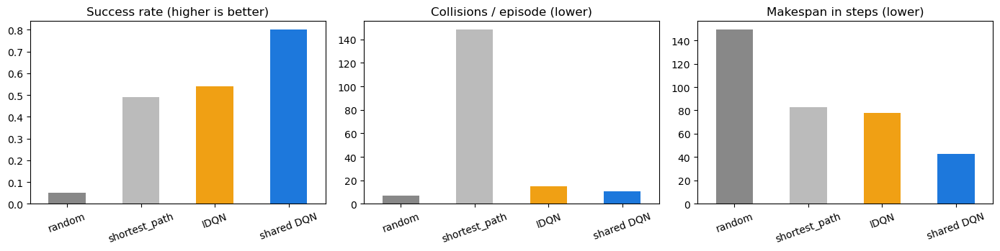

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, metric, title in zip(axes, ["success_rate", "collisions_per_episode", "avg_makespan"],
                             ["Success rate (higher is better)", "Collisions / episode (lower)", "Makespan in steps (lower)"]):
    results_2[metric].plot(kind="bar", ax=ax, color=["#888", "#bbb", "#f0a014", "#1d78dc"])
    ax.set_title(title); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.savefig("results/comparison_2_robots.png", dpi=150); plt.show()

### Training curves

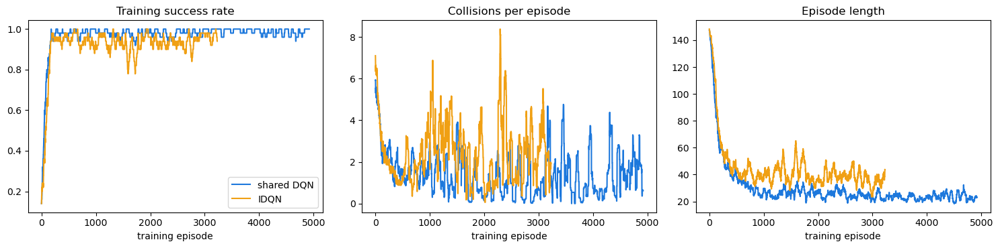

In [15]:
def smooth(x, k=50):
    x = np.asarray(x, float)
    return np.convolve(x, np.ones(k) / k, mode="valid") if len(x) > k else x

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for log, label, col in [(log_shared, "shared DQN", "#1d78dc"), (log_idqn, "IDQN", "#f0a014")]:
    for ax, key, title in zip(axes, ["success", "collisions", "length"],
                              ["Training success rate", "Collisions per episode", "Episode length"]):
        ax.plot(smooth(log[key], 50 if not QUICK else 5), label=label, color=col)
        ax.set_title(title); ax.set_xlabel("training episode")
axes[0].legend(); plt.tight_layout(); plt.savefig("results/training_curves.png", dpi=150); plt.show()

##
We also try a *tiny* amount of random exploration at test time (ε = 0.02)

In [16]:
def failure_report(policy, layout="aisle", n_robots=2, episodes=100, eps=0.0):
    
    old_eps, policy.eps = policy.eps, eps
    np.random.seed(0)                                   
    env = WarehouseEnv(layout, n_robots, **ENV_KW)
    ok = quiet = jam = 0
    for ep in range(episodes):
        obs, _ = env.reset(seed=10_000 + ep); done = False
        while not done:
            obs, _, terminated, truncated, info = env.step(policy(env, obs))
            done = terminated or truncated
        if info["success"]:             ok += 1
        elif info["collisions"] <= 20:  quiet += 1       
        else:                           jam += 1         
    policy.eps = old_eps
    return {"test eps": eps, "success": ok, "quiet stall": quiet, "collision jam": jam}

pd.DataFrame([failure_report(pol_shared, eps=e, episodes=EVAL_EPISODES) for e in (0.0, 0.02)]).set_index("test eps")

,success,quiet stall,collision jam
test eps,,,
0.00,80,15,5
0.02,96,3,1


## 12. The simulation

 Here we run the trained policies in the Gymnasium environment.

Shortest-path baseline (watch for the deadlock):


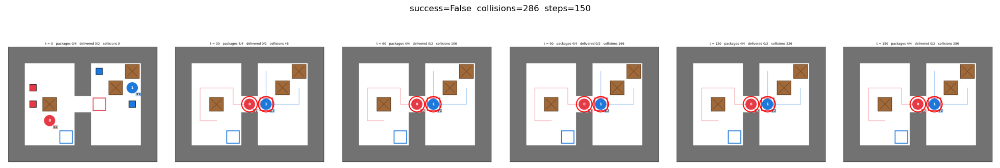

Shared DQN:


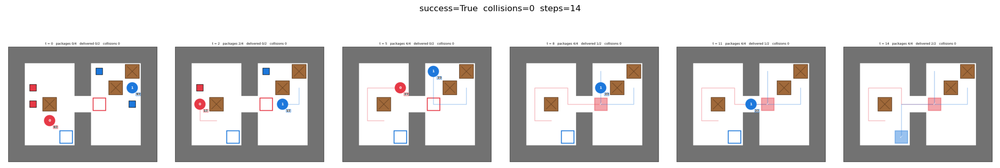

saved results/shared_dqn_aisle_2.gif
saved results/greedy_aisle_2.gif
saved results/simulation_aisle_2.gif and results/simulation_aisle_2.html


In [17]:
def record_episode(policy, layout, n_robots, seed, **env_kw):
    """Run one episode through the Gymnasium API and capture env.render() after every step."""
    env = WarehouseEnv(layout, n_robots, render_mode="rgb_array", **{**ENV_KW, **env_kw})
    obs, _ = env.reset(seed=seed)
    frames, done = [env.render()], False
    while not done:
        obs, _, terminated, truncated, info = env.step(policy(env, obs))
        done = terminated or truncated
        frames.append(env.render())
    return frames, info

def show_snapshots(policy, layout, n_robots, seed, max_panels=6):
    frames, info = record_episode(policy, layout, n_robots, seed)
    idxs = np.linspace(0, len(frames) - 1, min(max_panels, len(frames))).astype(int)
    fig, axes = plt.subplots(1, len(idxs), figsize=(3.3 * len(idxs), 3.2))
    for ax, k in zip(np.atleast_1d(axes), idxs):
        ax.imshow(frames[k]); ax.axis("off")
    plt.suptitle(f"success={info['success']}  collisions={info['collisions']}  steps={info['t']}", y=1.02)
    plt.tight_layout(); plt.show()

def save_gif(policy, layout, n_robots, seed, path):
    frames, _ = record_episode(policy, layout, n_robots, seed)
    imgs = [Image.fromarray(f) for f in frames]
    imgs[0].save(path, save_all=True, append_images=imgs[1:], duration=350, loop=0)
    print("saved", path)

def show_simulation(policies, layout, n_robots, seed, fps=3, save_as=None):
    runs = {name: record_episode(p, layout, n_robots, seed) for name, p in policies.items()}
    T = max(len(fr) for fr, _ in runs.values())
    fig, axes = plt.subplots(1, len(runs), figsize=(4.8 * len(runs), 4.4))
    axes, ims = np.atleast_1d(axes), []
    for ax, (name, (fr, info)) in zip(axes, runs.items()):
        ims.append(ax.imshow(fr[0])); ax.axis("off")
        verdict = "SUCCESS" if info["success"] else "FAILED / deadlock"
        ax.set_title(f"{name}\n{verdict} | collisions {info['collisions']} | {info['t']} steps", fontsize=10)
    def update(k):
        for im, (fr, _) in zip(ims, runs.values()):
            im.set_data(fr[min(k, len(fr) - 1)])          
        return ims
    anim = animation.FuncAnimation(fig, update, frames=T, interval=1000 / fps, blit=False)
    plt.close(fig)
    html = anim.to_jshtml(fps=fps)
    if save_as:
        anim.save(save_as + ".gif", writer=animation.PillowWriter(fps=fps))
        with open(save_as + ".html", "w") as f:
            f.write(html)
        print("saved", save_as + ".gif and", save_as + ".html")
    return HTML(html)

print("Shortest-path baseline (watch for the deadlock):")
show_snapshots(greedy_policy, "aisle", 2, seed=10_003)
print("Shared DQN:")
show_snapshots(pol_shared, "aisle", 2, seed=10_003)
save_gif(pol_shared, "aisle", 2, 10_003, "results/shared_dqn_aisle_2.gif")
save_gif(greedy_policy, "aisle", 2, 10_003, "results/greedy_aisle_2.gif")

display(show_simulation({"shortest-path (no coordination)": greedy_policy, "shared DQN": pol_shared},
                        "aisle", 2, seed=10_003, save_as="results/simulation_aisle_2"))

### The trained policy inside a plain Gymnasium loop


In [18]:
env = gym.make("MultiRobotWarehouse-v0", layout="aisle", n_robots=2,
               render_mode="rgb_array", disable_env_checker=True, **ENV_KW)
obs, info = env.reset(seed=10_003)
raw, frames, done, total = env.unwrapped, [env.render()], False, 0.0
while not done:
    actions = pol_shared(raw, obs)                      
    obs, rewards, terminated, truncated, info = env.step(actions)
    done = terminated or truncated
    total += rewards.sum(); frames.append(env.render())
print(f"success={info['success']} | steps={info['t']} | collisions={info['collisions']} | team return={total:.2f}")
env.close()

success=True | steps=14 | collisions=0 | team return=42.80


## 13. Scaling up: curriculum from 2 to 4 robots


In [19]:
pol_shared_4, log_shared_4, ev_shared_4 = train("shared", "aisle", 4, steps=STEPS_4, seed=SEED,
                                                init_from=pol_shared, eval_every=EVAL_EVERY, name="shared 2→4")
rows = []
for n in (2, 4):
    for name, pol in [("random", random_policy), ("shortest_path", greedy_policy),
                      ("shared (trained on 2)", pol_shared), ("shared (curriculum 2→4)", pol_shared_4)]:
        rows.append({"policy": name, "n_robots": n, **evaluate(pol, "aisle", n, EVAL_EPISODES)})
scaling_df = pd.DataFrame(rows).round(2)
scaling_df.to_csv("results/scaling.csv", index=False)
scaling_df

[shared 2→4] step   10000 | eps 0.84 | eval success 0.20 | packages 0.69 | collisions 71.83 | makespan 126.0 | 30s
[shared 2→4] step   20000 | eps 0.68 | eval success 0.07 | packages 0.64 | collisions 70.83 | makespan 141.9 | 73s
[shared 2→4] step   30000 | eps 0.53 | eval success 0.17 | packages 0.71 | collisions 73.57 | makespan 129.5 | 115s
[shared 2→4] step   40000 | eps 0.37 | eval success 0.13 | packages 0.69 | collisions 98.37 | makespan 134.0 | 158s
[shared 2→4] step   50000 | eps 0.21 | eval success 0.57 | packages 0.85 | collisions 88.83 | makespan 80.6 | 201s
[shared 2→4] step   60000 | eps 0.05 | eval success 0.47 | packages 0.80 | collisions 76.83 | makespan 91.9 | 250s
[shared 2→4] step   70000 | eps 0.05 | eval success 0.40 | packages 0.78 | collisions 56.23 | makespan 100.7 | 292s
[shared 2→4] step   80000 | eps 0.05 | eval success 0.57 | packages 0.86 | collisions 45.80 | makespan 80.5 | 335s
[shared 2→4] step   90000 | eps 0.05 | eval success 0.37 | packages 0.78 | co

,policy,n_robots,success_rate,deadlock_or_timeout_rate,packages_picked_frac,collisions_per_episode,avg_makespan,sum_of_costs,throughput_per_100_steps
0,random,2,0.07,0.93,0.68,7.93,147.11,277.62,0.61
1,shortest_path,2,0.49,0.51,0.74,148.16,82.86,163.91,2.37
2,shared (trained on 2),2,0.80,0.20,0.94,10.46,42.63,71.12,7.88
3,shared (curriculum 2→4),2,0.72,0.28,0.91,19.87,53.23,88.32,5.82
4,random,4,0.00,1.00,0.64,46.57,150.00,560.92,0.92
5,shortest_path,4,0.01,0.99,0.40,533.81,148.66,549.86,0.48
6,shared (trained on 2),4,0.43,0.57,0.75,41.38,98.95,348.22,4.02
7,shared (curriculum 2→4),4,0.52,0.48,0.80,33.24,86.36,281.33,5.70


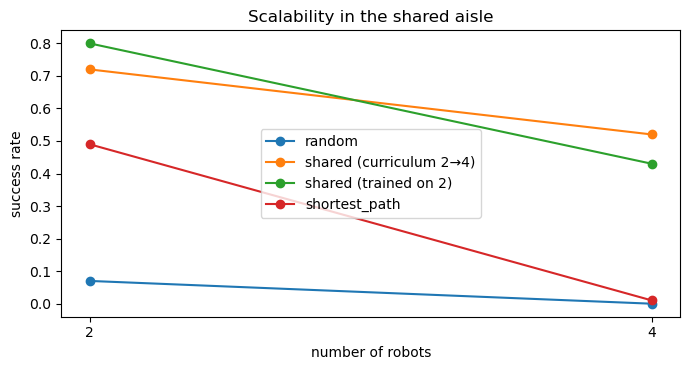

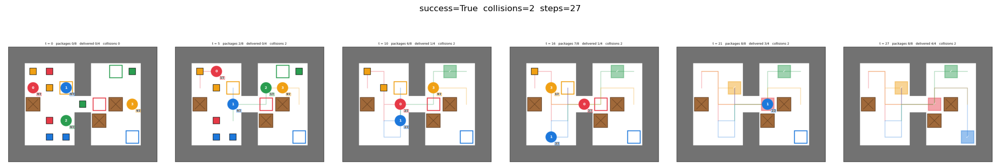

saved results/simulation_aisle_4.gif and results/simulation_aisle_4.html


In [20]:
fig, ax = plt.subplots(figsize=(7, 3.8))
for name, g in scaling_df.groupby("policy"):
    ax.plot(g["n_robots"], g["success_rate"], marker="o", label=name)
ax.set_xticks([2, 4]); ax.set_xlabel("number of robots"); ax.set_ylabel("success rate")
ax.set_title("Scalability in the shared aisle"); ax.legend(); plt.tight_layout()
plt.savefig("results/scalability.png", dpi=150); plt.show()
show_snapshots(pol_shared_4, "aisle", 4, seed=10_005)
display(show_simulation({"shortest-path (no coordination)": greedy_policy, "shared (curriculum 2→4)": pol_shared_4},
                        "aisle", 4, seed=10_005, save_as="results/simulation_aisle_4"))


**Generalisation test .** Does the policy trained on aisle work on the unseen warehouse layout

In [21]:
rows = []
for name, pol in [("shortest_path", greedy_policy), ("shared (curriculum 2→4)", pol_shared_4)]:
    rows.append({"policy": name, "layout": "warehouse (unseen)", **evaluate(pol, "warehouse", 4, EVAL_EPISODES)})
pd.DataFrame(rows).round(2)

,policy,layout,success_rate,deadlock_or_timeout_rate,packages_picked_frac,collisions_per_episode,avg_makespan,sum_of_costs,throughput_per_100_steps
0,shortest_path,warehouse (unseen),0.02,0.98,0.49,448.49,147.41,480.70,1.21
1,shared (curriculum 2→4),warehouse (unseen),0.00,1.00,0.41,15.64,150.00,535.09,0.67


## 14. Ablations

In [22]:
variants = {
    "full":                 dict(),
    "no shaping":           dict(use_shaping=False),
    "no collision penalty": dict(collision_penalty=0.0),
    "weak collision pen.":  dict(collision_penalty=-0.5),
    "no pickup bonus":      dict(pickup_reward=0.0),
}
rows = []
for vname, kw in variants.items():
    pol, _, _ = train("shared", "aisle", 2, steps=STEPS_ABL, seed=SEED, eval_every=max(1000, STEPS_ABL // 4),
                      verbose=False, name=vname, **kw)
    rows.append({"variant": vname, **evaluate(pol, "aisle", 2, EVAL_EPISODES)})
    print("done:", vname)
ablation_df = pd.DataFrame(rows).round(2).set_index("variant")
ablation_df.to_csv("results/ablation.csv")
ablation_df[["success_rate", "collisions_per_episode", "avg_makespan"]]

done: full
done: no shaping
done: no collision penalty
done: weak collision pen.
done: no pickup bonus


,success_rate,collisions_per_episode,avg_makespan
variant,,,
full,0.69,21.61,57.37
no shaping,0.67,2.96,60.34
no collision penalty,0.64,47.21,63.67
weak collision pen.,0.82,15.97,39.33
no pickup bonus,0.42,24.78,93.70


## 15. Multiple seeds (2 methods × 3 seeds)

In [23]:
if RUN_MULTISEED:
    rows = []
    for seed in (0, 1, 2):
        for mode in ("shared", "independent"):
            pol, _, _ = train(mode, "aisle", 2, steps=STEPS_2, seed=seed, eval_every=EVAL_EVERY,
                              verbose=False, name=f"{mode}-s{seed}")
            rows.append({"method": mode, "seed": seed, **evaluate(pol, "aisle", 2, EVAL_EPISODES)})
            print("done:", mode, "seed", seed)
    seeds_df = pd.DataFrame(rows)
    summary = seeds_df.groupby("method")[["success_rate", "collisions_per_episode", "avg_makespan"]].agg(["mean", "std"]).round(3)
    seeds_df.to_csv("results/multiseed_raw.csv", index=False)
    display(summary)
else:
    print("Skipped. Set RUN_MULTISEED = True in Section 1 to run it.")

done: shared seed 0
done: independent seed 0
done: shared seed 1
done: independent seed 1
done: shared seed 2
done: independent seed 2


success_rate        collisions_per_episode        avg_makespan  \
                    mean    std                   mean    std         mean   
method                                                                       
independent        0.577  0.091                 18.807  5.171       73.017   
shared             0.760  0.053                  8.230  2.004       48.143   

                     
                std  
method               
independent  11.906  
shared        7.111